# Comparative analysis — English figures

English version of `compare.ipynb`. Same data, same statistical procedures and plot
settings; only the text in the figures is translated, using the article's terminology
(Heuristic, Random, BC 8K/32K/131K, SPI, ICE).

Figures are written to `analysis/images/en/` with the file names used by the article
(`figures/` in the article repository).

In [1]:
import sys
from pathlib import Path

import pandas as pd

notebook_dir = Path().resolve()
sys.path.insert(0, str(notebook_dir.parent))

from tools import violinplot_with_bootstrap_test, violinplot_with_overlap, bootstrap_pairwise_heatmap

# Every bootstrap test draws from its own generator seeded with SEED, so the
# p-values (and the figures) are identical on every run.
SEED = 42

SAVE_DIR = "../analysis/images/en"
DATA_DIR = Path("../analysis/data")

## Data

In [2]:
# (directory, results file) for each behavior, per scenario.
#   scenario key -> (formation, 'ratio friend:enemy')
SCENARIOS = {
    "":                (False, "1:1"),
    "_formation":      (True,  "1:1"),
    "_asym":           (False, "0.7:1"),
    "_formation_asym": (True,  "0.7:1"),
    "_asym_m":         (False, "1:0.7"),
    "_formation_asym_m": (True, "1:0.7"),
}

FILES = {
    "proposal": {
        "":                  "results_2025_06_14_08h53m59s.csv",
        "_formation":        "results_2025_06_13_14h18m06s.csv",
        "_asym":             "results_2025_06_15_01h01m22s.csv",
        "_formation_asym":   "results_2025_06_15_11h30m55s.csv",
        "_asym_m":           "results_2025_06_19_10h14m17s.csv",
        "_formation_asym_m": "results_2025_06_21_12h24m17s.csv",
    },
    "baseline": {
        "":                  "results_2026_01_15_21h18m43s.csv",
        "_formation":        "results_2026_01_14_22h05m51s.csv",
        "_asym":             "results_2026_01_16_22h32m11s.csv",
        "_formation_asym":   "results_2026_01_17_14h58m04s.csv",
        "_asym_m":           "results_2026_01_20_20h51m35s.csv",
        "_formation_asym_m": "results_2026_01_18_15h04m08s.csv",
    },
}
BC_FILES = {
    "":                  "results_2026_01_12_12h22m15s.csv",
    "_formation":        "results_2026_01_13_21h38m22s.csv",
    "_asym":             "results_2026_01_23_07h19m59s.csv",
    "_formation_asym":   "results_2026_01_14_11h57m39s.csv",
    "_asym_m":           "results_2026_01_22_17h17m06s.csv",
    "_formation_asym_m": "results_2026_01_24_22h57m40s.csv",
}
for n in (8192, 32768, 131072):
    FILES[f"behavior_cloning_{n}"] = BC_FILES

# Directory prefix -> behavior name used in the article
BEHAVIOR = {
    "proposal":                "Heuristic",
    "baseline":                "Random",
    "behavior_cloning_8192":   "BC 8K",
    "behavior_cloning_32768":  "BC 32K",
    "behavior_cloning_131072": "BC 131K",
}
BEHAVIOR_ORDER = list(BEHAVIOR.values())
RATIO_ORDER = ["0.7:1", "1:1", "1:0.7"]

frames = []
for prefix, files in FILES.items():
    for scenario, fname in files.items():
        df = pd.read_csv(DATA_DIR / f"{prefix}{scenario}" / fname)
        formation, ratio = SCENARIOS[scenario]
        df["simulation"] = BEHAVIOR[prefix]
        df["formation"] = formation
        df["ratio friend:enemy"] = ratio
        frames.append(df)

data = pd.concat(frames, ignore_index=True)
data.groupby(["simulation", "ratio friend:enemy", "formation"]).size().unstack()

formation                      False  True 
simulation ratio friend:enemy              
BC 131K    0.7:1                 200    200
           1:0.7                 200    200
           1:1                   200    200
BC 32K     0.7:1                 200    200
           1:0.7                 200    200
           1:1                   200    200
BC 8K      0.7:1                 200    200
           1:0.7                 200    200
           1:1                   200    200
Heuristic  0.7:1                 200    200
           1:0.7                 200    200
           1:1                   200    200
Random     0.7:1                 200    200
           1:0.7                 200    200
           1:1                   200    200

In [3]:
# Shared text
FORMATION_LEGEND = dict(legend_title="Attacker in\nFormation", legend_labels={True: "Yes", False: "No"})
RATIO_XLABEL = "Defender-to-attacker numerical ratio"
SPI_YLABEL = "Point-of-Interest Health — SPI (%)"
ICE_YLABEL = "Energy Consumption Index — ICE"
BOX_LABELS = {"title": "BOOTSTRAP TEST", "insufficient": "Insufficient data",
              "rejected": "H₀ rejected", "not_rejected": "H₀ not rejected"}
HEATMAP_TEXT = dict(sig_label="p < α  (sig.)", nonsig_label="p ≥ α  (not sig.)",
                    correction_prefix="Correction", no_correction_label="none")
HEATMAP_SUBTITLE = "Two-sided pairwise bootstrap test  |  * p < 0.05  |  B = 10,000 iterations"

# Defensive effectiveness (SPI)

### Behavior → by formation and ratio

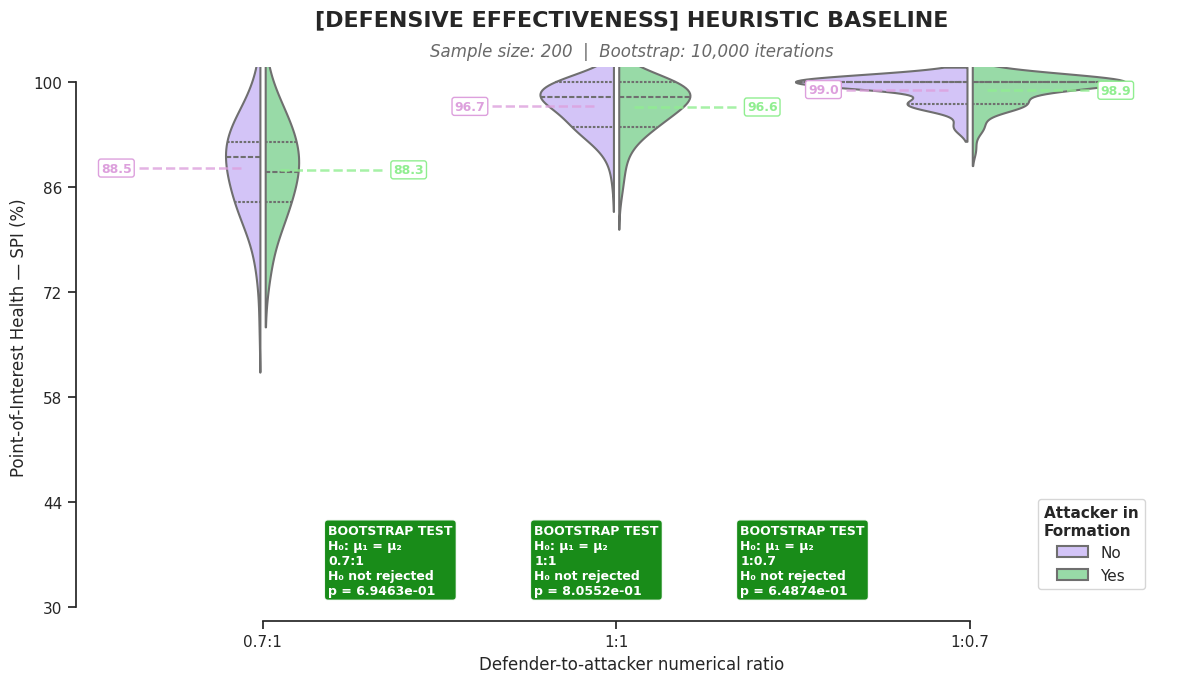

In [4]:
test_result = violinplot_with_bootstrap_test(
    data=data,
    filter_conditions={"simulation": "Heuristic"},
    x_col="ratio friend:enemy",
    y_col="interest_point_health",
    hue_col="formation",
    title="[DEFENSIVE EFFECTIVENESS] HEURISTIC BASELINE",
    subtitle="Sample size: 200  |  Bootstrap: 10,000 iterations",
    xlabel=RATIO_XLABEL,
    ylabel=SPI_YLABEL,
    n_bootstrap=10_000,
    alpha=0.01,
    figsize=(12, 7),
    split=True,
    gap=0.03,
    fill=True,
    linewidth=1.5,
    palette=["m", "g"],
    density_norm="area",
    width=1,
    common_norm=True,
    bw_adjust=1.6,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="spi-heuristic",
    **FORMATION_LEGEND,
    box_labels=BOX_LABELS,
    seed=SEED,
    inner="quart",
    x_order=RATIO_ORDER,
    ylim_bottom=30,
    ylim_top=100,
)

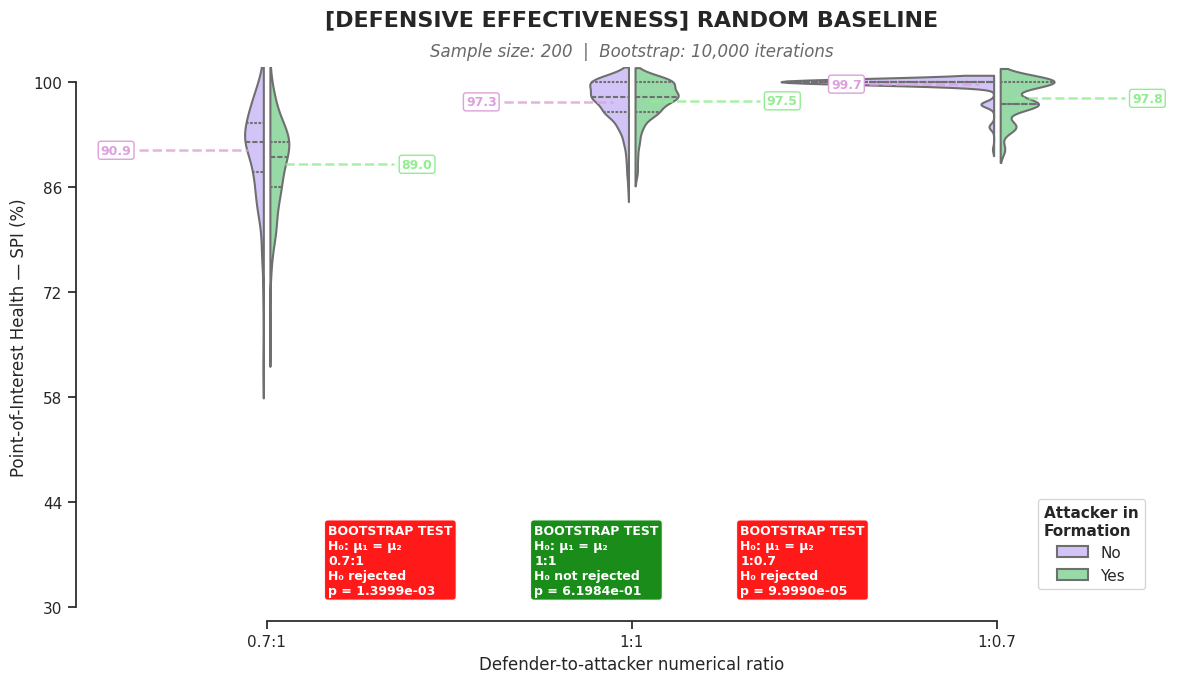

In [5]:
test_result = violinplot_with_bootstrap_test(
    data=data,
    filter_conditions={"simulation": "Random"},
    x_col="ratio friend:enemy",
    y_col="interest_point_health",
    hue_col="formation",
    title="[DEFENSIVE EFFECTIVENESS] RANDOM BASELINE",
    subtitle="Sample size: 200  |  Bootstrap: 10,000 iterations",
    xlabel=RATIO_XLABEL,
    ylabel=SPI_YLABEL,
    n_bootstrap=10_000,
    alpha=0.01,
    figsize=(12, 7),
    split=True,
    gap=0.03,
    fill=True,
    linewidth=1.5,
    palette=["m", "g"],
    density_norm="area",
    width=1.2,
    common_norm=True,
    bw_adjust=1.0,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="spi-random",
    **FORMATION_LEGEND,
    box_labels=BOX_LABELS,
    seed=SEED,
    inner="quart",
    x_order=RATIO_ORDER,
    ylim_bottom=30,
    ylim_top=100,
)

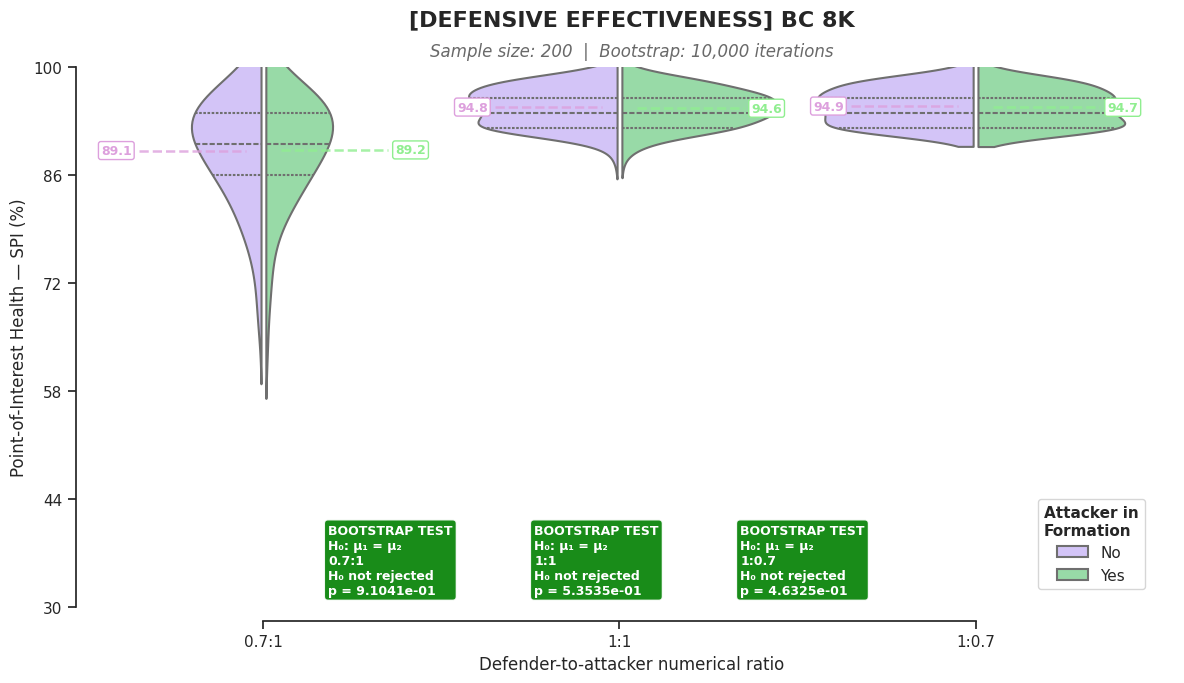

In [6]:
test_result = violinplot_with_bootstrap_test(
    data=data,
    filter_conditions={"simulation": "BC 8K"},
    x_col="ratio friend:enemy",
    y_col="interest_point_health",
    hue_col="formation",
    title="[DEFENSIVE EFFECTIVENESS] BC 8K",
    subtitle="Sample size: 200  |  Bootstrap: 10,000 iterations",
    xlabel=RATIO_XLABEL,
    ylabel=SPI_YLABEL,
    n_bootstrap=10_000,
    alpha=0.01,
    figsize=(12, 7),
    split=True,
    gap=0.03,
    fill=True,
    linewidth=1.5,
    palette=["m", "g"],
    density_norm="area",
    width=0.9,
    common_norm=False,
    bw_adjust=1.5,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="spi-bc-8k",
    **FORMATION_LEGEND,
    box_labels=BOX_LABELS,
    seed=SEED,
    inner="quart",
    x_order=RATIO_ORDER,
    ylim_bottom=30,
    ylim_top=100,
)

#### Summary — by ratio

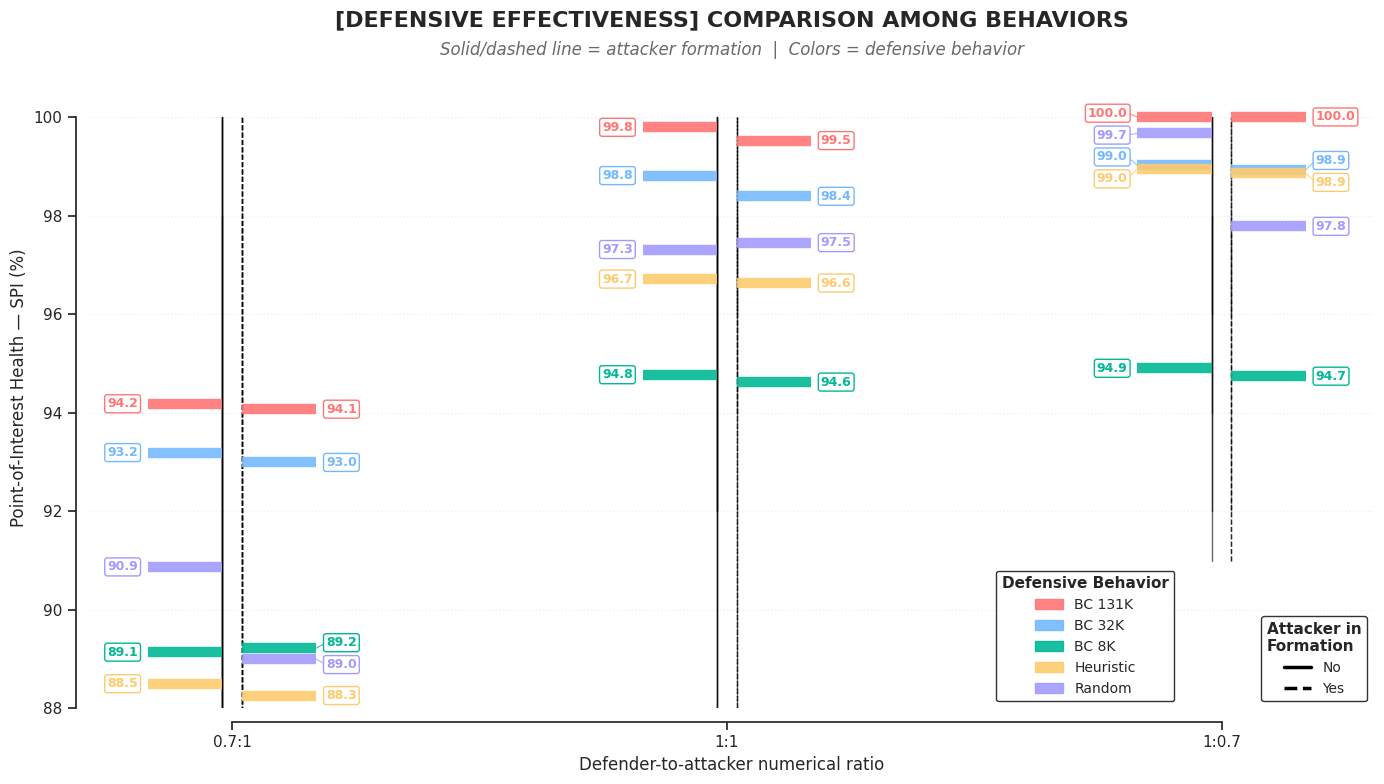

In [7]:
test_result = violinplot_with_overlap(
    data=data,
    x_col="ratio friend:enemy",
    y_col="interest_point_health",
    hue_col="formation",
    hue2_col="simulation",
    title="[DEFENSIVE EFFECTIVENESS] COMPARISON AMONG BEHAVIORS",
    subtitle="Solid/dashed line = attacker formation  |  Colors = defensive behavior",
    xlabel=RATIO_XLABEL,
    ylabel=SPI_YLABEL,
    figsize=(14, 8),
    linewidth=0.5,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="spi-comparison-by-ratio",
    **FORMATION_LEGEND,
    hue2_legend_title="Defensive Behavior",
    x_order=RATIO_ORDER,
    ylim_top=101,
    ylim_bottom=88,
    hemisphere_mode="split",
)

#### Summary — by behavior (article figure `spi-comparison`)

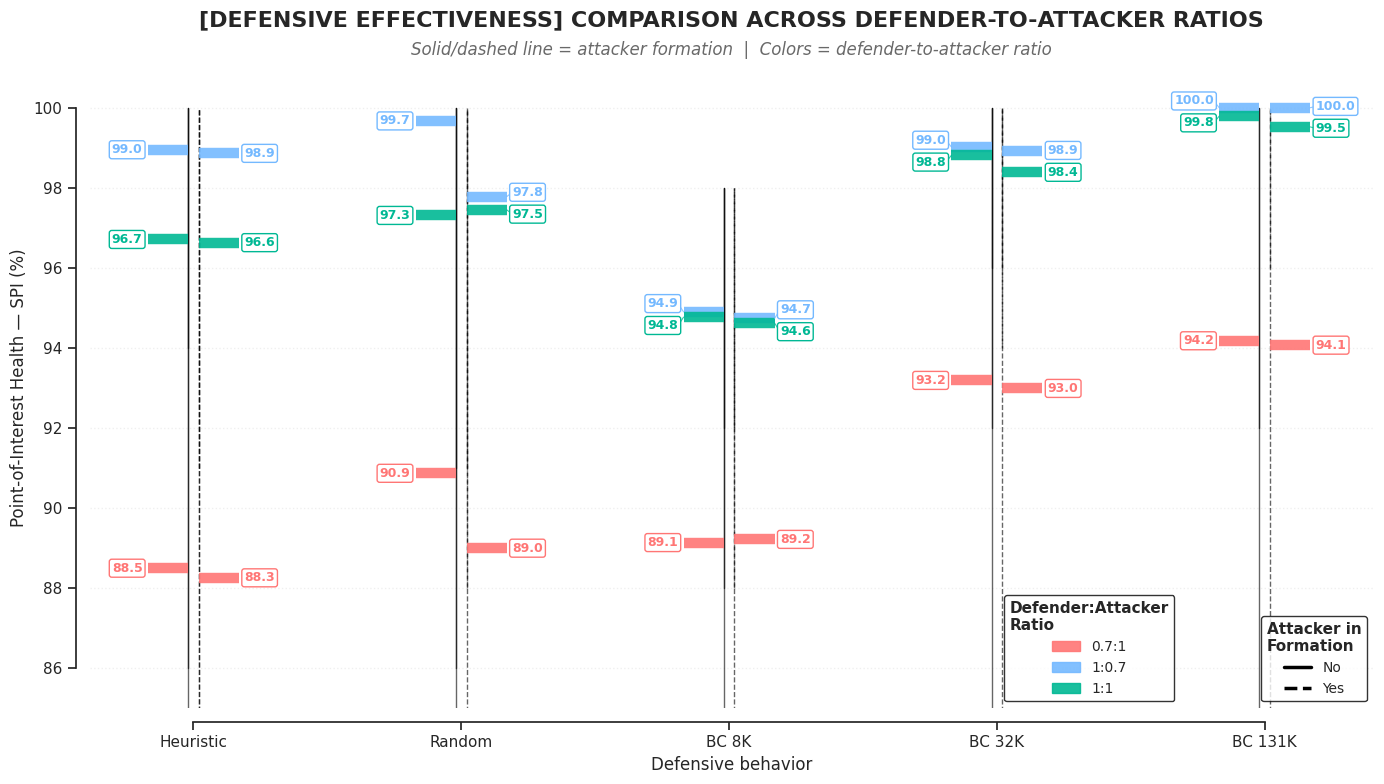

In [8]:
test_result = violinplot_with_overlap(
    data=data,
    x_col="simulation",
    y_col="interest_point_health",
    hue_col="formation",
    hue2_col="ratio friend:enemy",
    title="[DEFENSIVE EFFECTIVENESS] COMPARISON ACROSS DEFENDER-TO-ATTACKER RATIOS",
    subtitle="Solid/dashed line = attacker formation  |  Colors = defender-to-attacker ratio",
    xlabel="Defensive behavior",
    ylabel=SPI_YLABEL,
    figsize=(14, 8),
    linewidth=0.5,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="spi-comparison",
    **FORMATION_LEGEND,
    hue2_legend_title="Defender:Attacker\nRatio",
    x_order=BEHAVIOR_ORDER,
    ylim_top=101,
    ylim_bottom=85,
    hemisphere_mode="split",
)

# Energy consumption (ICE)

#### Summary — by behavior (article figure `ice-comparison`)

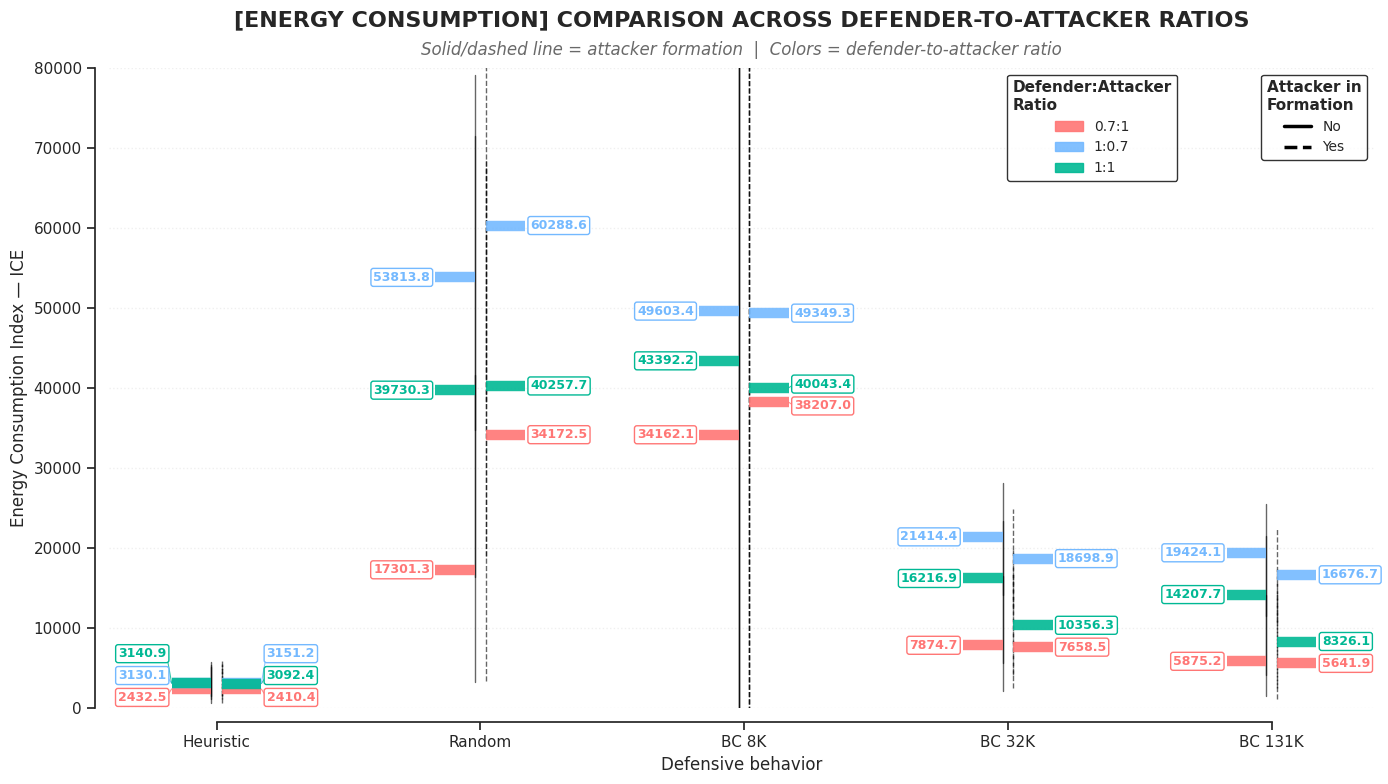

In [9]:
test_result = violinplot_with_overlap(
    data=data,
    x_col="simulation",
    y_col="total_distance_traveled",
    hue_col="formation",
    hue2_col="ratio friend:enemy",
    title="[ENERGY CONSUMPTION] COMPARISON ACROSS DEFENDER-TO-ATTACKER RATIOS",
    subtitle="Solid/dashed line = attacker formation  |  Colors = defender-to-attacker ratio",
    xlabel="Defensive behavior",
    ylabel=ICE_YLABEL,
    figsize=(14, 8),
    linewidth=0.5,
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="ice-comparison",
    **FORMATION_LEGEND,
    hue2_legend_title="Defender:Attacker\nRatio",
    x_order=BEHAVIOR_ORDER,
    ylim_top=80000,
    ylim_bottom=0,
    hemisphere_mode="split",
    loc="upper right",
)

# Pairwise bootstrap tests

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


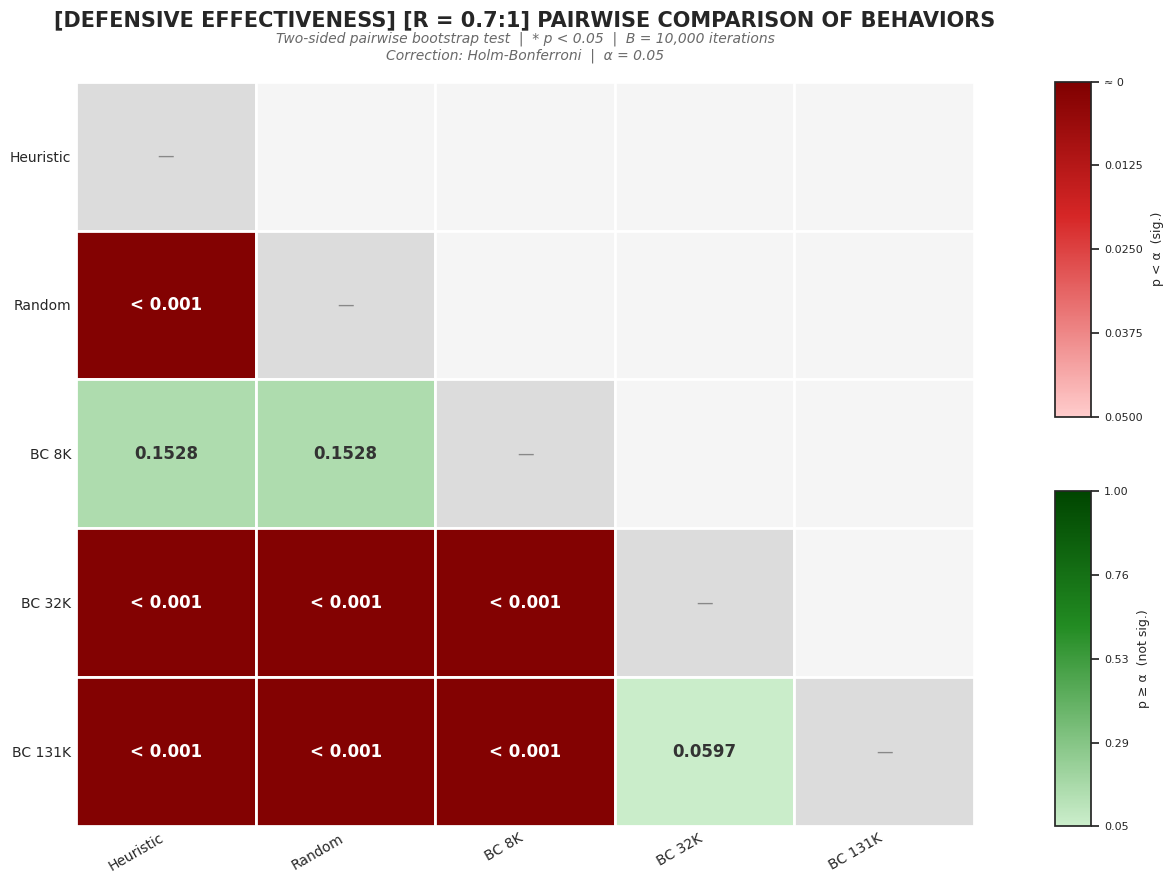

BOOTSTRAP PAR A PAR  —  variável: interest_point_health  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 8K                     0.076392      0.152785  ⭕ não significativo
  Heuristic             BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                     0.097290      0.152785  ⭕ não significativo
  Random                BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8

In [10]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="interest_point_health",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "0.7:1"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[DEFENSIVE EFFECTIVENESS] [R = 0.7:1] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-spi-disadvantage",
)

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


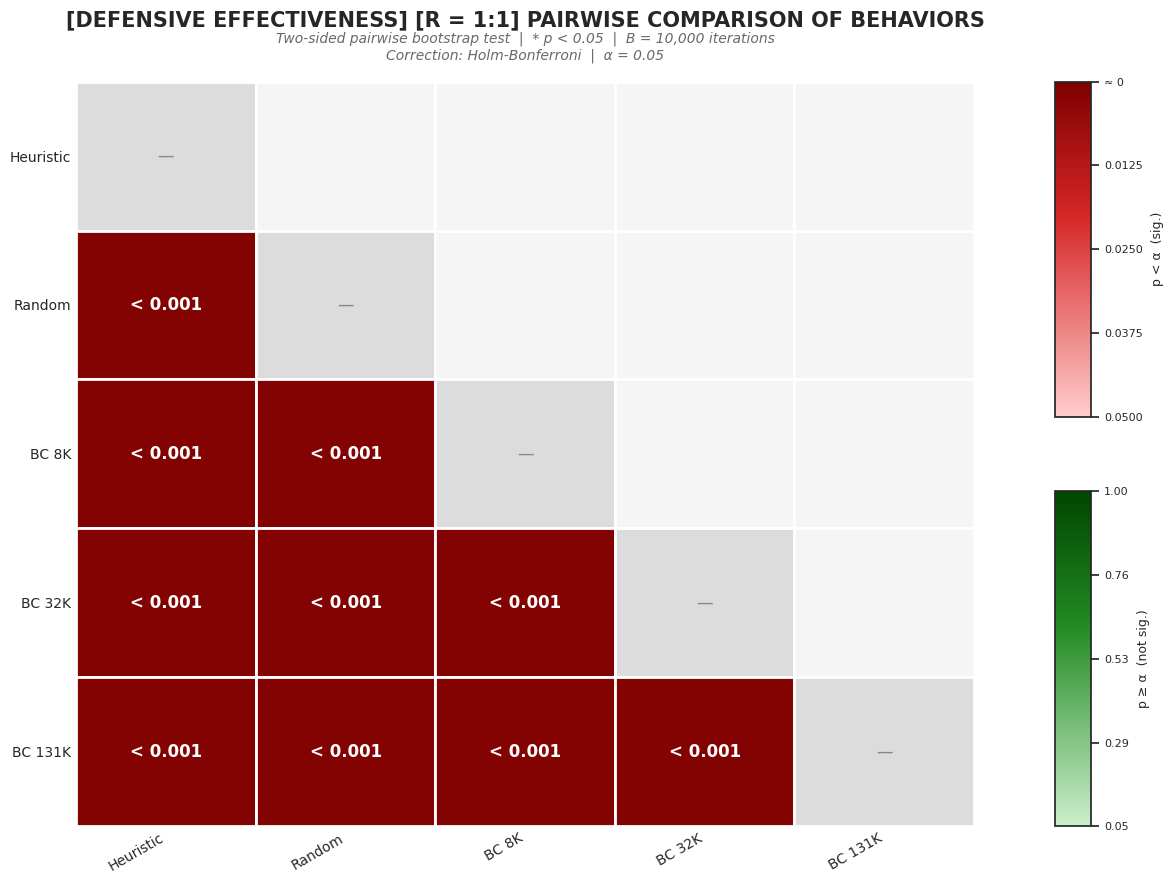

BOOTSTRAP PAR A PAR  —  variável: interest_point_health  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC

In [11]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="interest_point_health",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "1:1"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[DEFENSIVE EFFECTIVENESS] [R = 1:1] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-spi-parity",
)

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


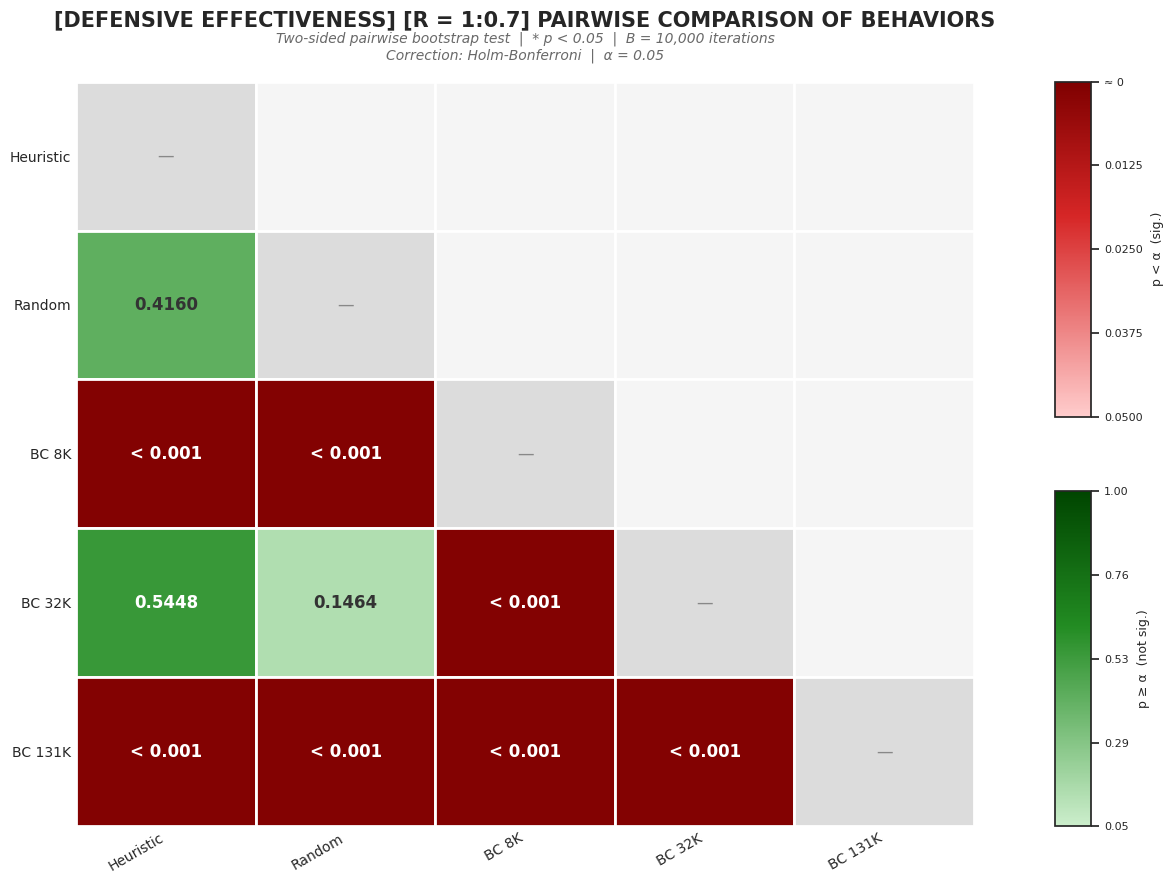

BOOTSTRAP PAR A PAR  —  variável: interest_point_health  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                    0.207979      0.415958  ⭕ não significativo
  Heuristic             BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 32K                    0.544846      0.544846  ⭕ não significativo
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 32K                    0.048795      0.146385  ⭕ não significativo
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICAT

In [12]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="interest_point_health",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "1:0.7"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[DEFENSIVE EFFECTIVENESS] [R = 1:0.7] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-spi-advantage",
)

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


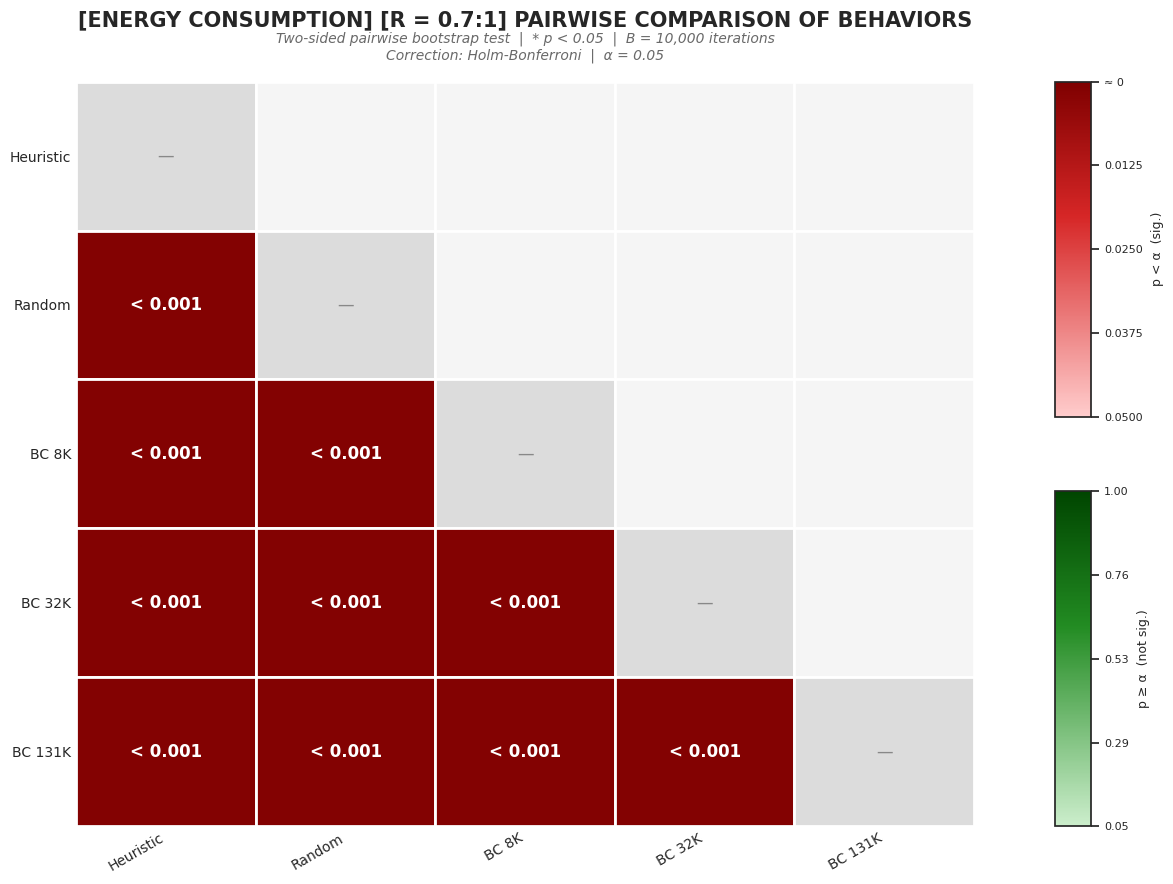

BOOTSTRAP PAR A PAR  —  variável: total_distance_traveled  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 

In [13]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="total_distance_traveled",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "0.7:1"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[ENERGY CONSUMPTION] [R = 0.7:1] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-ice-disadvantage",
)

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


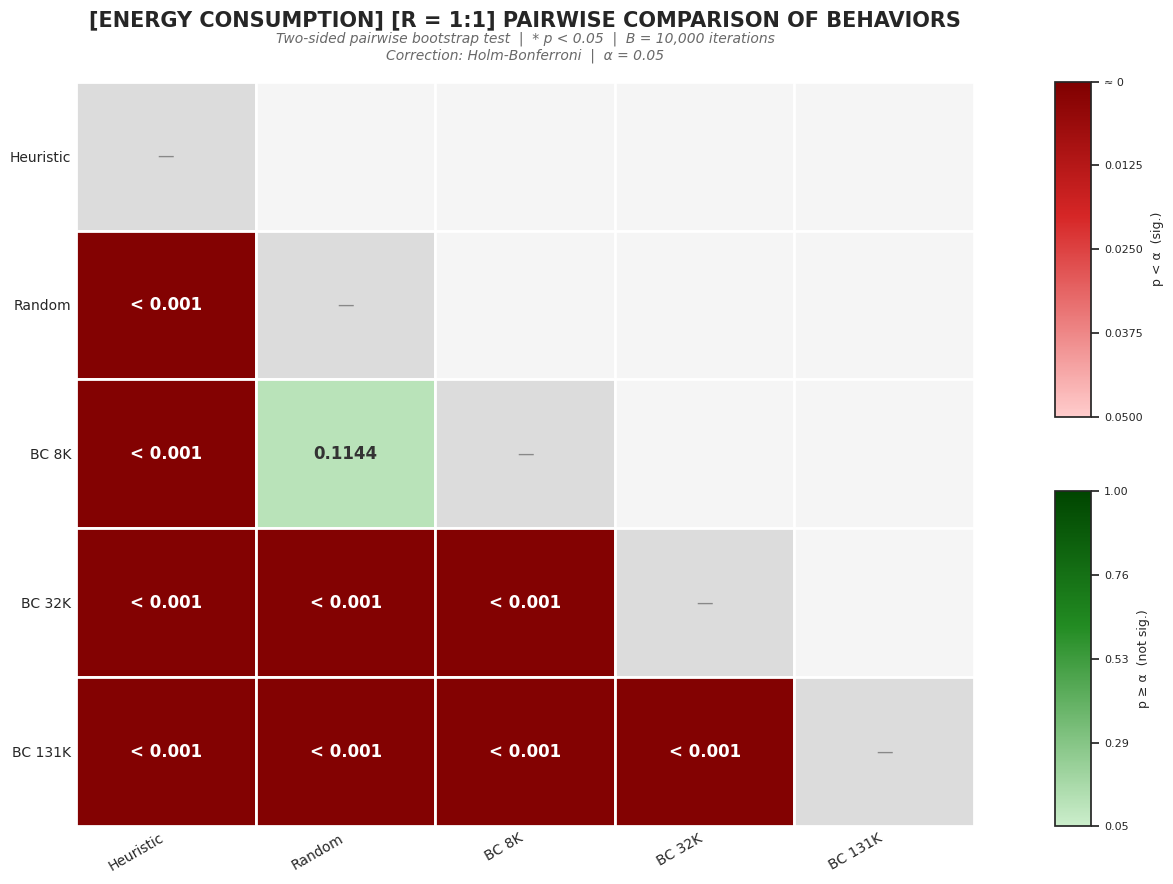

BOOTSTRAP PAR A PAR  —  variável: total_distance_traveled  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                     0.114389      0.114389  ⭕ não significativo
  Random                BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K       

In [14]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="total_distance_traveled",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "1:1"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[ENERGY CONSUMPTION] [R = 1:1] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-ice-parity",
)

/home/lucas/Projects/droneswarm2d-imitation-thesis/tools/compare.py:1312: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


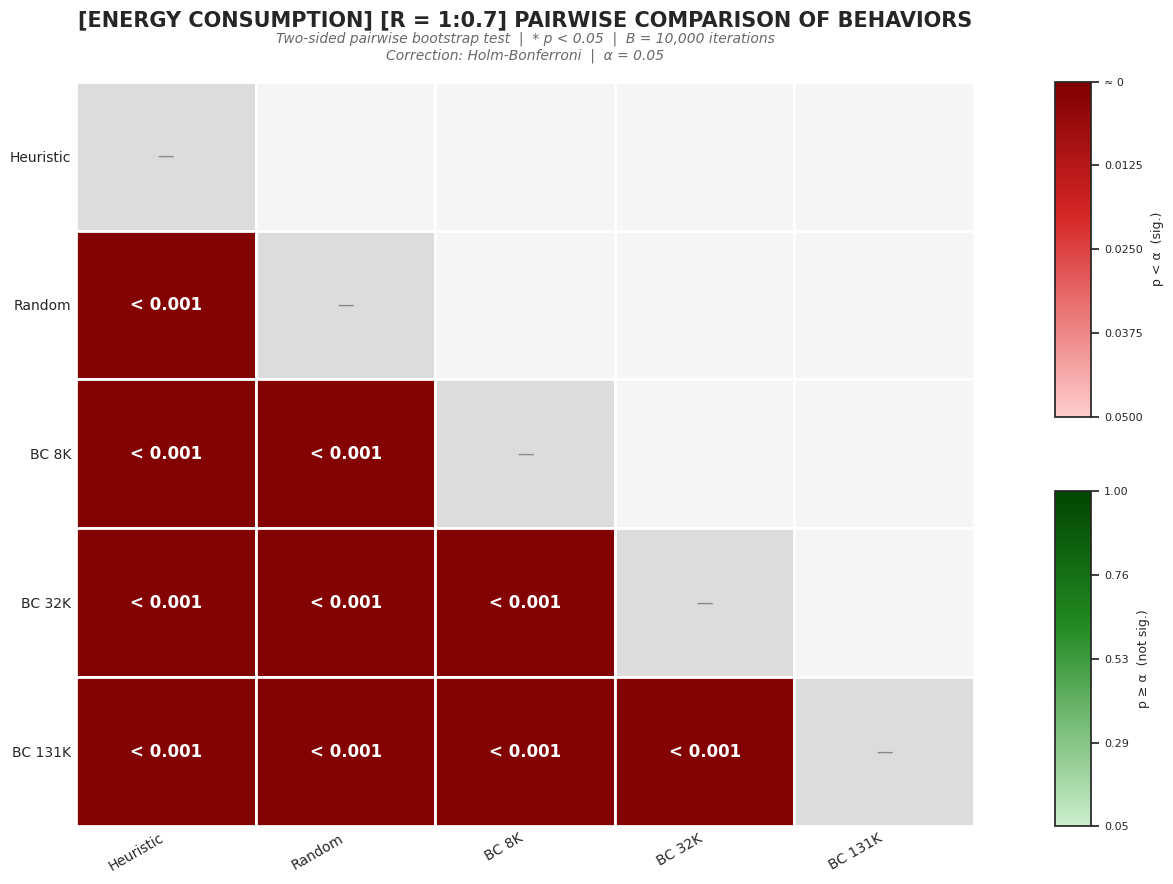

BOOTSTRAP PAR A PAR  —  variável: total_distance_traveled  |  α = 0.05
Iterações: 10,000  |  Comparações: 10  |  Correção: Holm-Bonferroni
  Grupo A               Grupo B                  p (bruto)   p (corrig.)  Resultado
--------------------------------------------------------------------------------
  Heuristic             Random                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Heuristic             BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 8K                   < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  Random                BC 131K                 < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 BC 32K                  < 0.001    < 0.001  ✅ SIGNIFICATIVO
  BC 8K                 

In [15]:
results = bootstrap_pairwise_heatmap(
    data=data,
    y_col="total_distance_traveled",
    group_col="simulation",
    filter_conditions={"ratio friend:enemy": "1:0.7"},
    group_order=BEHAVIOR_ORDER,
    annot_fontsize=12,
    n_bootstrap=10_000,
    correction="holm",
    alpha=0.05,
    seed=SEED,
    title="[ENERGY CONSUMPTION] [R = 1:0.7] PAIRWISE COMPARISON OF BEHAVIORS",
    subtitle=HEATMAP_SUBTITLE,
    **HEATMAP_TEXT,
    figsize=(10, 9),
    save_fig=True,
    save_dir=SAVE_DIR,
    filename="bootstrap-ice-advantage",
)